C:\Users\athul\AppData\Local\Temp\ipykernel_33992\3391977638.py:69: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(


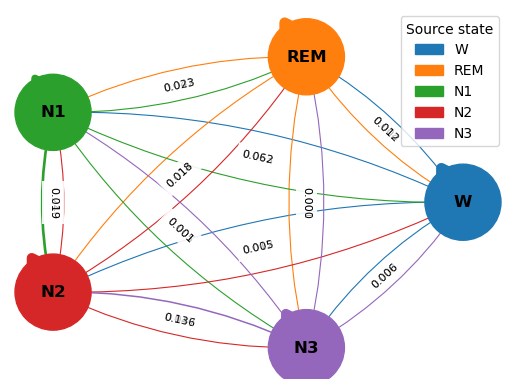

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Create directed graph
G = nx.DiGraph()

states = ['W', 'REM', 'N1', 'N2', 'N3']

# Add transitions (example values — replace with yours)
edges = [
    # From W
    ('W', 'W', 0.9379),
    ('W', 'REM', 0.0035),
    ('W', 'N1', 0.0530),
    ('W', 'N2', 0.0118),
    ('W', 'N3', 0.0003),

    # From REM
    ('REM', 'W', 0.0116),
    ('REM', 'REM', 0.9474),
    ('REM', 'N1', 0.0422),
    ('REM', 'N2', 0.0137),
    ('REM', 'N3', 0.0007),

    # From N1
    ('N1', 'W', 0.0618),
    ('N1', 'REM', 0.0229),
    ('N1', 'N1', 0.6546),
    ('N1', 'N2', 0.2405),
    ('N1', 'N3', 0.0055),

    # From N2
    ('N2', 'W', 0.0050),
    ('N2', 'REM', 0.0177),
    ('N2', 'N1', 0.0195),
    ('N2', 'N2', 0.9080),
    ('N2', 'N3', 0.0467),

    # From N3
    ('N3', 'W', 0.0062),
    ('N3', 'REM', 0.0001),
    ('N3', 'N1', 0.0006),
    ('N3', 'N2', 0.1357),
    ('N3', 'N3', 0.8516),
]

# Add edges to graph
for u, v, w in edges:
    G.add_edge(u, v, weight=w)

# Color map for edges originating from the same state
colors_map = {'W': 'tab:blue', 'REM': 'tab:orange', 'N1': 'tab:green', 'N2': 'tab:red', 'N3': 'tab:purple'}

# Layout
pos = nx.circular_layout(G)

# Node colors (match origin colors to help visual association)
node_colors = [colors_map[s] for s in states]
nx.draw_networkx_nodes(G, pos, node_size=3000, node_color=node_colors)

# Prepare edge drawing parameters
edgelist = [(u, v) for u, v, w in edges]
edge_colors = [colors_map[u] for u, v, w in edges]
# Scale widths so larger probabilities are visually stronger
edge_widths = [max(0.8, w * 8) for u, v, w in edges]

# Draw edges with arrows, color-coded by origin, and slight curvature
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=edgelist,
    edge_color=edge_colors,
    width=edge_widths,
    arrows=True,
    arrowsize=24,
    arrowstyle='-|>',
    connectionstyle='arc3,rad=0.12'
)

# Draw node labels
nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold')

# Format edge labels to 3 decimal places (or percentage if you prefer)
edge_labels = {(u, v): f'{w:.3f}' for u, v, w in edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, label_pos=0.5, bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))

# Legend showing source-state colors
legend_handles = [Patch(color=colors_map[s], label=s) for s in states]
plt.legend(handles=legend_handles, title='Source state', loc='upper right')

plt.axis('off')
plt.show()
